In [77]:
import numpy as np
import matplotlib.pyplot as plt

import finufft

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances

In [78]:
class Transform():
    """
    TODO:
    - add normalization to cdf, icdf
    - add signed transform function
    - add modes for different Fourier point spacing
    - different interpolation method for icdf
    - allow for odd or even signal size
    """

    def __init__(self, f, d, omega=None, theta=None, phi=None, n_points=None, apply_ramp=False):

        self.f = f.astype(np.complex128)  # required type for nufft
        self.d = d  # dimension of input signal
        self.omega = omega
        self.theta = theta
        self.phi = phi
        self.n_points = n_points
        self.apply_ramp = apply_ramp
        self.shape = f.shape

        if d == 2 and len(self.shape) == 3:
            self.n, self.ny, self.nx = self.shape
        elif d == 2 and len(self.shape) == 2:
            self.n, self.ny, self.nx = 1, self.shape[0], self.shape[1]

        if d == 3 and len(self.shape) == 4:
            self.n, self.nz, self.ny, self.nx = f.shape
        elif d == 3 and len(self.shape) == 3:
            self.n, self.nz, self.ny, self.nx = 1, self.shape[0], self.shape[1], self.shape[2]

        if self.omega is None:
            self.omega = np.linspace(0, 2*np.pi, self.ny, endpoint=False)
        if self.theta is None:
            self.theta = np.linspace(0, 2*np.pi, self.ny, endpoint=False)
        if self.phi is None:
            self.phi = np.linspace(0, 2*np.pi, self.ny, endpoint=False)
        if self.n_points is None:
            self.n_points = self.ny

        self.n_omega = self.omega.size
        self.n_theta = self.theta.size
        self.n_phi = self.phi.size

        if apply_ramp:
            self.ramp = np.abs(np.linspace(-(1 - (1/self.n_points)), 1 - (1/self.n_points), self.n_points, endpoint=True))


    def get_2d_to_1d_fourier_slice_points(self, mode=0):
        """mode: controls point spacings for 1D Fourier slices (0 = Cartesian, 1 = Chebyshev)"""

        ### initial Fourier points along y-axis
        if mode == 0:
            y = np.linspace(-(1 - (1/self.n_points)), 1 - (1/self.n_points), self.n_points, endpoint=True) 
        elif mode == 1:
            assert "Chebyshev points not implemented yet"
    
        ### rotate by omega (around z-axis)
        x_omega = y[:, np.newaxis] * np.sin(self.omega)[np.newaxis, :]
        y_omega = y[:, np.newaxis] * np.cos(self.omega)[np.newaxis, :]
        
        ### format for fiNUFFT
        y_omega = np.pi * y_omega.flatten()
        x_omega = np.pi * x_omega.flatten()
    
        return x_omega, y_omega


    def get_3d_to_1d_fourier_slice_points(self, mode=0):
        """mode controls point spacings for 1D Fourier slices (0 = Cartesian, 1 = Chebyshev, 2 = Fibonacci)"""
    
        ### initial Fourier points along z-axis
        if mode == 0:
            z = np.linspace(-(1 - (1/self.n_points)), 1 - (1/self.n_points), self.n_points, endpoint=True)
        elif mode == 1:
            assert "Chebyshev points not implemented yet"
        elif mode == 2:
            assert "Fibonacci points not implemented yet"
    
        ### rotate central slice on z-axis by theta (around y-axis) to form xz-plane of 1D slices
        x_theta = z[:, np.newaxis] * np.sin(self.theta)[np.newaxis, :]
        y_theta = np.zeros((self.n_points, self.n_theta))
        z_theta = z[:, np.newaxis] * np.cos(self.theta)[np.newaxis, :]
        
        ### rotate each slice by phi (around the z-axis)
        x_theta_phi = x_theta[np.newaxis, ...] * np.cos(self.phi[:, np.newaxis, np.newaxis])
        y_theta_phi = x_theta[np.newaxis, ...] * np.sin(self.phi[:, np.newaxis, np.newaxis])
        z_theta_phi = np.ones((self.n_phi, self.n_points, self.n_theta)) * z_theta
        
        ### format for fiNUFFT
        x_theta_phi = np.pi * x_theta_phi.flatten()
        y_theta_phi = np.pi * y_theta_phi.flatten()
        z_theta_phi = np.pi * z_theta_phi.flatten()
    
        return x_theta_phi, y_theta_phi, z_theta_phi


    def compute_nufft(self, nufft_type=2, eps=1e-8):
    
        if self.d == 2:
            plan = finufft.Plan(nufft_type, (self.nx, self.ny), self.n, eps)
            x, y = self.get_2d_to_1d_fourier_slice_points(mode=0)
            plan.setpts(x, y)
        
            f_hat = plan.execute(self.f).reshape(self.n, self.n_points, self.n_omega)
        
            if self.apply_ramp:
                f_hat *= self.ramp[:, np.newaxis]

        elif self.d == 3:
            plan = finufft.Plan(nufft_type, (self.nx, self.ny, self.nz), self.n, eps)
            x, y, z = self.get_3d_to_1d_fourier_slice_points(mode=0)
            plan.setpts(x, y, z)
        
            f_hat = plan.execute(self.f).reshape(self.n, self.n_phi, self.n_points, self.n_theta)
        
            if self.apply_ramp:
                f_hat *= self.ramp[np.newaxis, :, np.newaxis]        
        
        return f_hat


    def radon_transform(self):

        f_hat = self.compute_nufft()

        if self.d == 2:
            f_rt = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(f_hat, axes=1), axis=1), axes=1).real

        elif self.d == 3:
            f_rt = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(f_hat, axes=2), axis=2), axes=2).real

        return f_rt


    def cdf_transform(self, rescale=True):

        f_rt = self.radon_transform()

        if self.d == 2:
            f_cdf = np.cumsum(f_rt, axis=1)
        elif self.d == 3:
            f_cdf = np.cumsum(f_rt, axis=2)

        return f_cdf


    def icdf_transform(self):

        f_cdf = self.cdf_transform()
        f_icdf = np.zeros(f_cdf.shape)
        xp = np.linspace(0, 1, self.n_points, endpoint=True)  # grid points for interpolation

        if self.d == 2:
            for n in range(self.n):
                for omega_idx in range(self.n_omega):
                    icdf = np.interp(xp, f_cdf[n, :, omega_idx], xp)
                    f_icdf[n, :, omega_idx] = icdf
            f_icdf[:, 0, :] = 0  # EV: ENFORCE BOUNDS (not sure why this helps)
            f_icdf[:, -1, :] = 1

        if self.d == 3:
            for n in range(self.n):
                for phi_idx in range(self.n_phi):
                    for theta_idx in range(self.n_theta):
                        f_icdf[n, phi_idx, :, theta_idx] = np.interp(xp, f_cdf[n, phi_idx, :, theta_idx], xp)
            f_icdf[:, :, 0, :] = 0  # EV: ENFORCE BOUNDS (not sure why this helps)
            f_icdf[:, :, -1, :] = 1

        return f_icdf

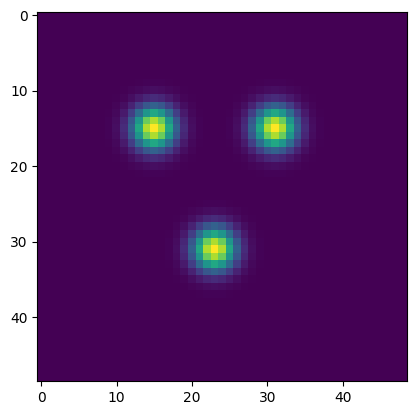

In [83]:
# f = utils.generate_3d_triangle_gaussian_shape(49, 2)
# f_rt = Transform(f, d=3, apply_ramp=True).radon_transform()
# plots.orthogonal_2D_projection_plot(f)

f = utils.generate_3d_triangle_gaussian_shape(49, 2)
f = f.sum(axis=0)
# f_rt = Transform(f, d=2, apply_ramp=False).radon_transform()
f_icdf = Transform(f, d=2, apply_ramp=False).icdf_transform()
plt.imshow(f)

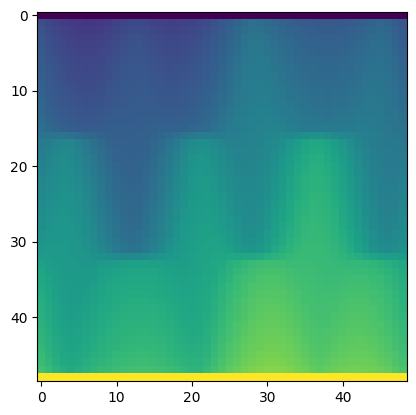

In [85]:
# plt.imshow(f_rt[0])
# plt.colorbar()
# plt.show()
# plt.plot(np.sum(f_rt[0], axis=0))

plt.imshow(f_icdf[0])

In [ ]:
def get_2d_to_1d_fourier_slice_points(n_points, omega, mode=0):
    """
    omega: angle to get central slices
    mode: controls point spacings for 1D Fourier slices (0 = Cartesian, 1 = Chebyshev)
    """

    omega = np.linspace(0, 2*np.pi, n_omega, endpoint=False)
    
    if mode == 0:
        y = np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True) # initial Fourier points along y-axis
    elif mode == 1:
        assert "Chebyshev points not implemented yet"

    ### rotate by omega (around z-axis)
    
    x_omega = y[:, np.newaxis] * np.sin(omega)[np.newaxis, :]
    y_omega = y[:, np.newaxis] * np.cos(omega)[np.newaxis, :]
    
    ### format for fiNUFFT

    y_omega = np.pi * y_omega.flatten()
    x_omega = np.pi * x_omega.flatten()

    return x_omega, y_omega


def get_3d_to_1d_fourier_slice_points(n_points, n_theta, n_phi, mode=0):
    """
    mode controls point spacings for 1D Fourier slices
    0 = Cartesian, 1 = Chebyshev, 2 = Fibonacci
    """

    if mode == 0:
        z = np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True)  # initial Fourier points along z-axis
    elif mode == 1:
        assert "Chebyshev points not implemented yet"
    elif mode == 2:
        assert "Fibonacci points not implemented yet"

    ### start with a central slice along the z-axis
    ### rotate by theta (around y-axis) to form xz-plane of 1D slices

    theta = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
    
    x_theta = z[:, np.newaxis] * np.sin(theta)[np.newaxis, :]
    y_theta = np.zeros((n_points, n_theta))
    z_theta = z[:, np.newaxis] * np.cos(theta)[np.newaxis, :]
    
    ### now rotate each slice by phi (around the z-axis)
    
    phi = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
    
    x_theta_phi = x_theta[np.newaxis, ...] * np.cos(phi[:, np.newaxis, np.newaxis])
    y_theta_phi = x_theta[np.newaxis, ...] * np.sin(phi[:, np.newaxis, np.newaxis])
    z_theta_phi = np.ones((n_phi, n_points, n_theta)) * z_theta
    
    ### format for fiNUFFT
    
    x_theta_phi = np.pi * x_theta_phi.flatten()
    y_theta_phi = np.pi * y_theta_phi.flatten()
    z_theta_phi = np.pi * z_theta_phi.flatten()

    return x_theta_phi, y_theta_phi, z_theta_phi


def compute_2d_nufft(f, n_points, n_omega, mode=0, apply_ramp=False, n_transforms=1, nufft_type=2, eps=1e-8):

    ny, nx = f.shape
    plan = finufft.Plan(nufft_type, (nx, ny), n_transforms, eps)
    x, y = get_2d_to_1d_fourier_slice_points(n_points, n_omega, mode)
    plan.setpts(x, y)

    f_hat = plan.execute(f.astype(np.complex128)).reshape(n_points, n_omega)

    if apply_ramp:
        ramp = np.abs(np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True))
        f_hat *= ramp[:, np.newaxis]
    
    return f_hat


def compute_3d_nufft(f, n_points, n_theta, n_phi, mode=0, apply_ramp=False, n_transforms=1, nufft_type=2, eps=1e-8):

    nz, ny, nx = f.shape
    plan = finufft.Plan(nufft_type, (nx, ny, nz), n_transforms, eps)
    x, y, z = get_3d_to_1d_fourier_slice_points(n_points, n_theta, n_phi, mode)
    plat.setpts(x, y, z)

    f_hat = plan.execute(f.astype(np.complex128)).reshape(n_phi, n_points, n_theta)

    if apply_ramp:
        ramp = np.abs(np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True))
        f_hat *= ramp[np.newaxis, :, np.newaxis]

    return f_hat
    

def radon_transform(f, d):

    if d == 2:
        f_hat = compute

In [ ]:
# images_ft = plan.execute(self.images).reshape(self.N, self.n_points, self.n_lines)

In [ ]:
def compute_projection_tensor_from_voxel_array(f):
    ### Notes
    ### - conventions are Cartesian-RHG, how to match with numpy-LHG?
    
    ### TODO
    ### - add input arguments, simplify, move inside transform class
    ### - add option to make different sampling points (Fibonacci, Chebyshev, etc)
    ### - change point spacing based on odd/even
    ### - update variables to match paper

    nz, ny, nx = f.shape
    
    ### EV: add option to change these if desired
    n_points = nz  # number of Fourier grid points per 1D slice, scales with volume size
    n_phi = nz  # number of projection angles in phi
    n_theta = nz  # number of projection angles in theta
    
    ### start with a central slice along the z-axis
    ### rotate by theta (around y-axis) to form xz-plane of 1D slices
    
    ### EV: TODO: define point spacing based on odd or even grid size (DFT conventions)
    z = np.linspace(-(1 - (1/n_points)), 1 - (1/n_points), n_points, endpoint=True)  # initial Fourier points along z-axis (x3)
    # z = np.linspace(-1, 1, n_points, endpoint=False)  # initial Fourier points along z-axis (x3)
    # z = np.linspace(1 - (1/n_points), -(1 - (1/n_points)), n_points, endpoint=True)
    
    theta = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
    
    x_theta = z[:, np.newaxis] * np.sin(theta)[np.newaxis, :]
    y_theta = np.zeros((n_points, n_theta))
    z_theta = z[:, np.newaxis] * np.cos(theta)[np.newaxis, :]
    
    ### now rotate each slice by phi (around the z-axis)
    
    phi = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
    
    x_theta_phi = x_theta[np.newaxis, ...] * np.cos(phi[:, np.newaxis, np.newaxis])
    y_theta_phi = x_theta[np.newaxis, ...] * np.sin(phi[:, np.newaxis, np.newaxis])
    z_theta_phi = np.ones((n_phi, n_points, n_theta)) * z_theta
    
    ### format for fiNUFFT
    
    x_theta_phi = np.pi * x_theta_phi.flatten()
    y_theta_phi = np.pi * y_theta_phi.flatten()
    z_theta_phi = np.pi * z_theta_phi.flatten()

    nufft_type=2
    eps=1e-8
    n_transforms=1
    
    plan = finufft.Plan(nufft_type, (nx, ny, nz), n_transforms, eps)
    
    ### EV: not sure what correct ordering is to match conventions
    plan.setpts(x_theta_phi, y_theta_phi, z_theta_phi)
    
    f_hat_slices = plan.execute(f.astype(np.complex128))
    f_hat_slices = f_hat_slices.reshape((n_phi, n_points, n_theta))
    
    f_projection_tensor = np.fft.fftshift(np.fft.ifft(np.fft.ifftshift(f_hat_slices, axes=1), axis=1), axes=1).real

    return f_projection_tensor